<a href="https://www.kaggle.com/code/mithhhilesh/brain-stroke-prediction-using-lr-dt-rf?scriptVersionId=358598935" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/jillanisofttech/brain-stroke-dataset/brain_stroke.csv


In [2]:
import numpy as np 
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
df = pd.read_csv('/kaggle/input/datasets/jillanisofttech/brain-stroke-dataset/brain_stroke.csv')

Exploring Dataset

In [3]:
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
2,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
3,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
4,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1


In [4]:
df.tail()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
4976,Male,41.0,0,0,No,Private,Rural,70.15,29.8,formerly smoked,0
4977,Male,40.0,0,0,Yes,Private,Urban,191.15,31.1,smokes,0
4978,Female,45.0,1,0,Yes,Govt_job,Rural,95.02,31.8,smokes,0
4979,Male,40.0,0,0,Yes,Private,Rural,83.94,30.0,smokes,0
4980,Female,80.0,1,0,Yes,Private,Urban,83.75,29.1,never smoked,0


Check Shape of Dataset

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4981 entries, 0 to 4980
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             4981 non-null   object 
 1   age                4981 non-null   float64
 2   hypertension       4981 non-null   int64  
 3   heart_disease      4981 non-null   int64  
 4   ever_married       4981 non-null   object 
 5   work_type          4981 non-null   object 
 6   Residence_type     4981 non-null   object 
 7   avg_glucose_level  4981 non-null   float64
 8   bmi                4981 non-null   float64
 9   smoking_status     4981 non-null   object 
 10  stroke             4981 non-null   int64  
dtypes: float64(3), int64(3), object(5)
memory usage: 428.2+ KB


In [6]:
df.shape

(4981, 11)

Check if null values exists

In [7]:
df.isnull().sum()

gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

Check of unique values

In [8]:
df.nunique()

gender                  2
age                   104
hypertension            2
heart_disease           2
ever_married            2
work_type               4
Residence_type          2
avg_glucose_level    3895
bmi                   342
smoking_status          4
stroke                  2
dtype: int64

Check of all columns

In [9]:
df.columns

Index(['gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='object')

Check unique values in respective columns

In [10]:
df_cat=df[['gender', 'hypertension', 'heart_disease', 'ever_married','work_type', 'Residence_type', 
                 'smoking_status', 'stroke']]

In [11]:
for i in df_cat.columns:
    print(df_cat[i].unique())

['Male' 'Female']
[0 1]
[1 0]
['Yes' 'No']
['Private' 'Self-employed' 'Govt_job' 'children']
['Urban' 'Rural']
['formerly smoked' 'never smoked' 'smokes' 'Unknown']
[1 0]


In [12]:
for i in df_cat.columns:
    print(df_cat[i].value_counts())

gender
Female    2907
Male      2074
Name: count, dtype: int64
hypertension
0    4502
1     479
Name: count, dtype: int64
heart_disease
0    4706
1     275
Name: count, dtype: int64
ever_married
Yes    3280
No     1701
Name: count, dtype: int64
work_type
Private          2860
Self-employed     804
children          673
Govt_job          644
Name: count, dtype: int64
Residence_type
Urban    2532
Rural    2449
Name: count, dtype: int64
smoking_status
never smoked       1838
Unknown            1500
formerly smoked     867
smokes              776
Name: count, dtype: int64
stroke
0    4733
1     248
Name: count, dtype: int64


Visualization of unique values using graphs/

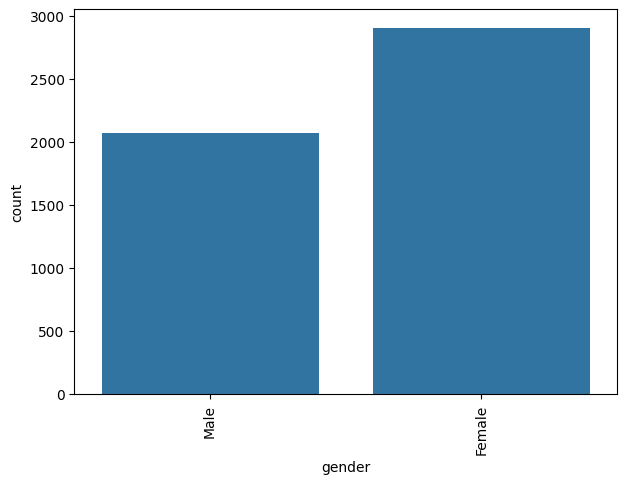

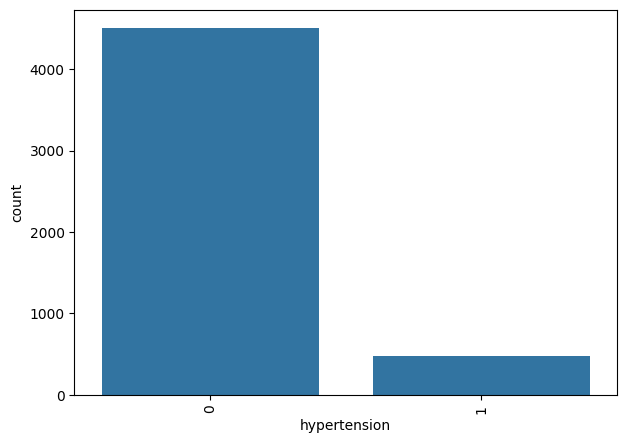

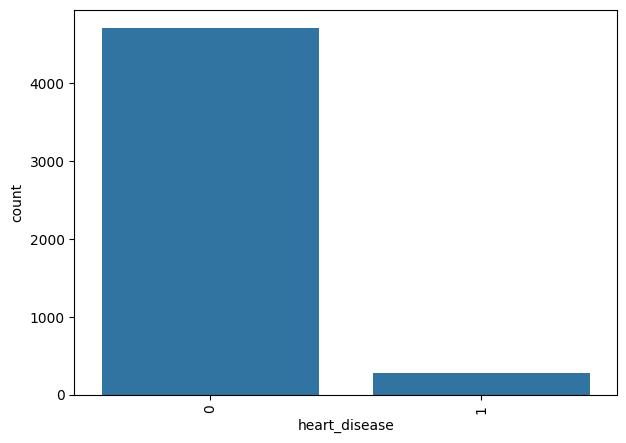

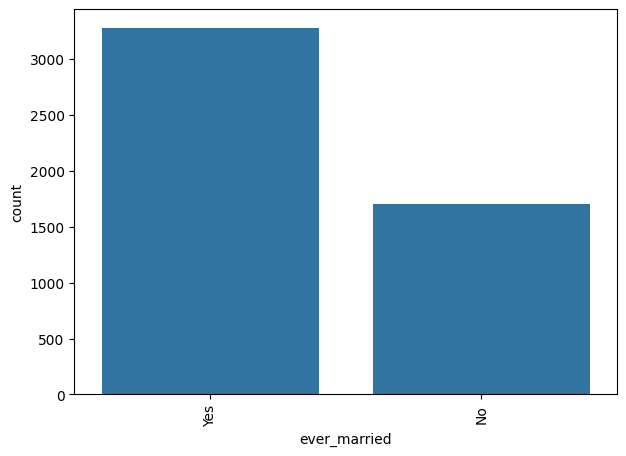

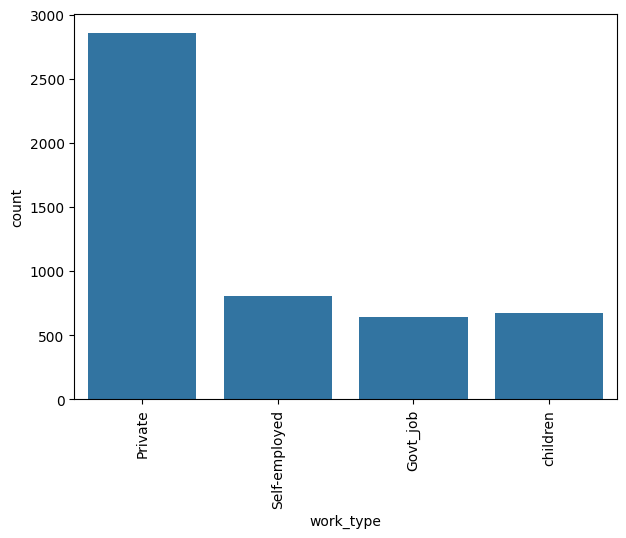

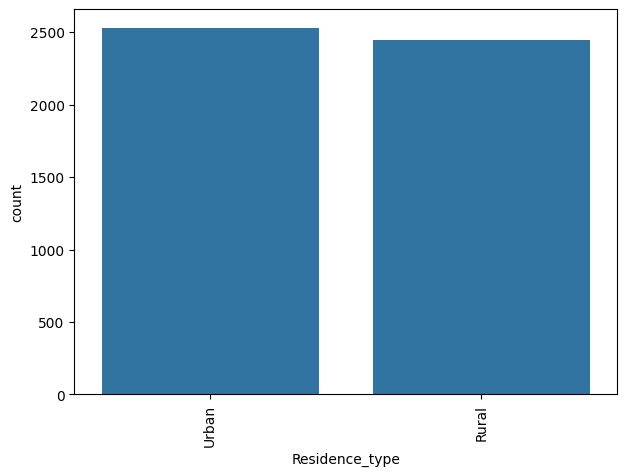

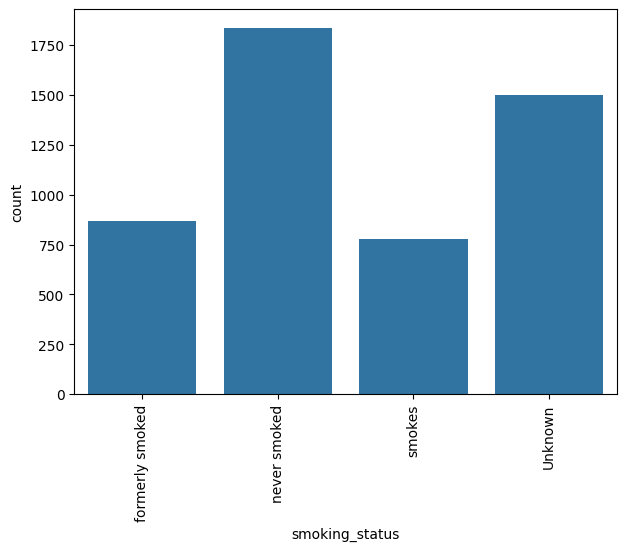

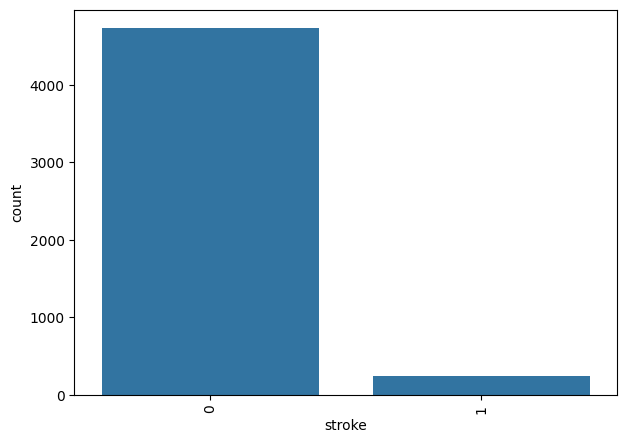

In [13]:
for i in df_cat.columns:
    plt.figure(figsize = (7,5))
    sns.countplot(x=df_cat[i])
    plt.xticks(rotation = 90)
    plt.show()

There is an oversampling in the dataset. There is a big difference between those who do not have a stroke and those who do.

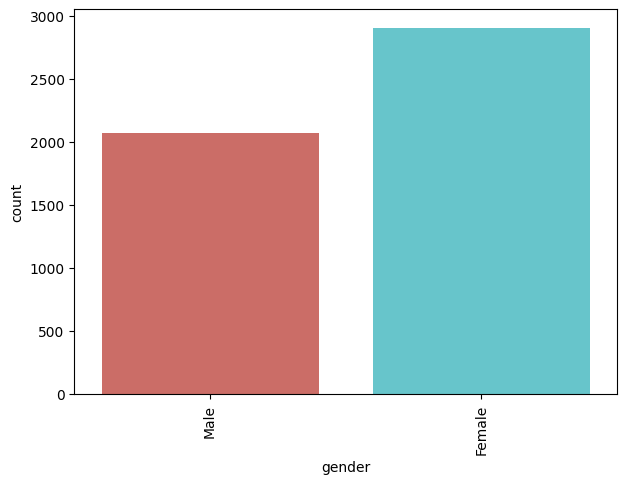

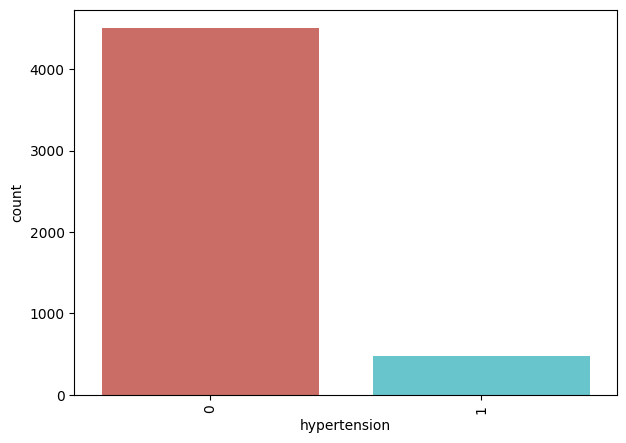

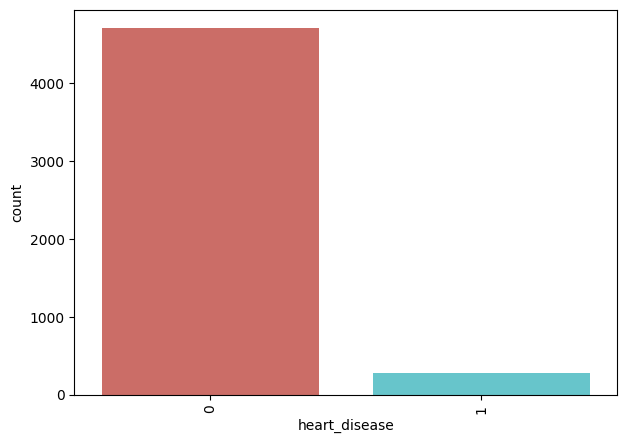

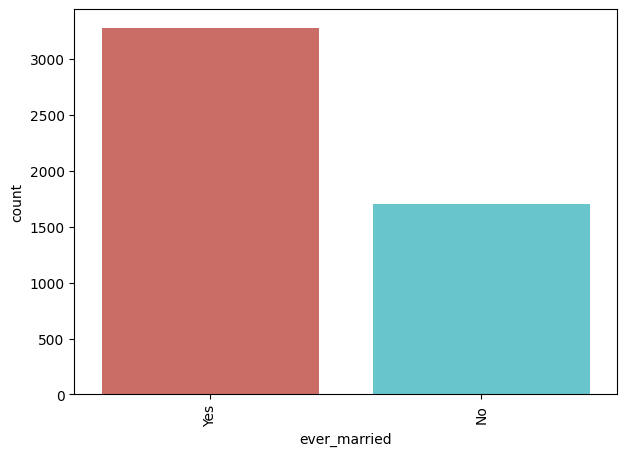

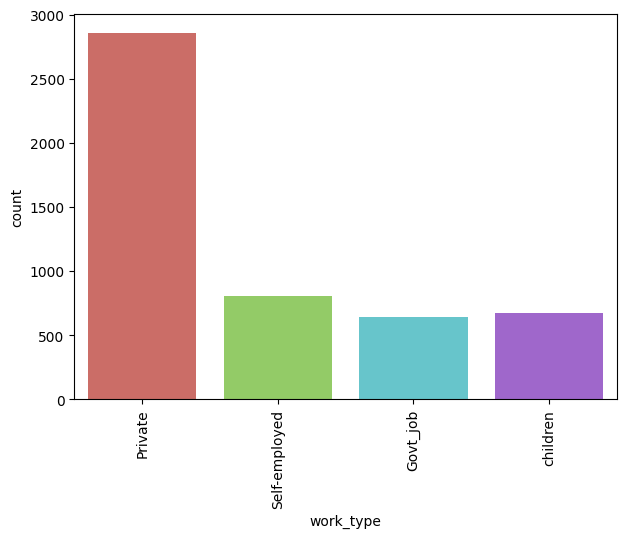

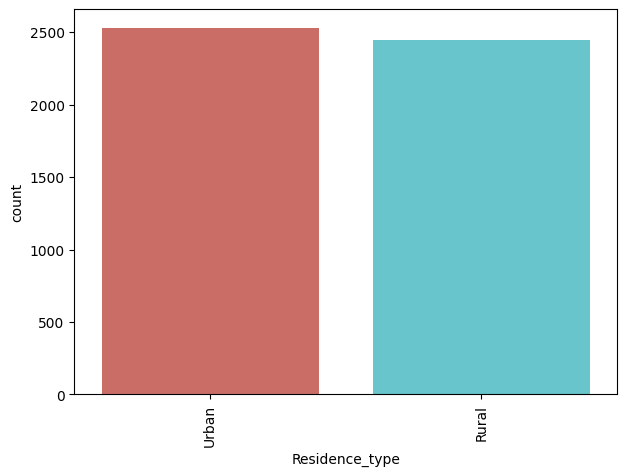

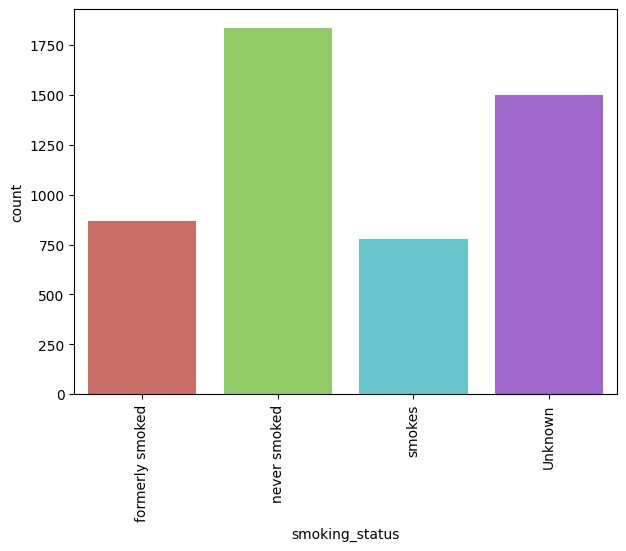

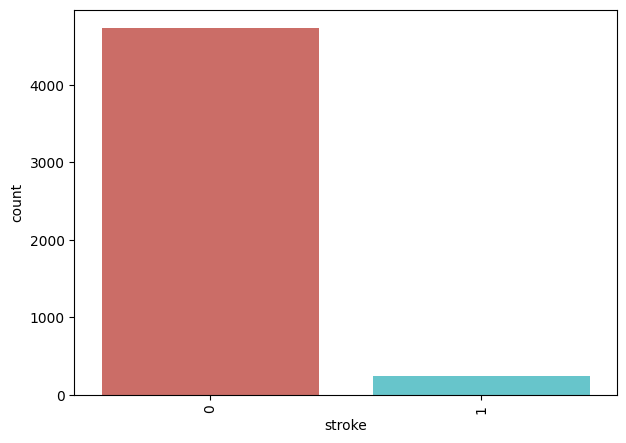

In [14]:
for i in df_cat.columns:
    plt.figure(figsize=(7,5))
    sns.countplot(x=i, data=df_cat, hue=i, palette='hls', legend=False)
    plt.xticks(rotation=90)
    plt.show()

In [15]:
df_num = df[['age', 'avg_glucose_level', 'bmi']]

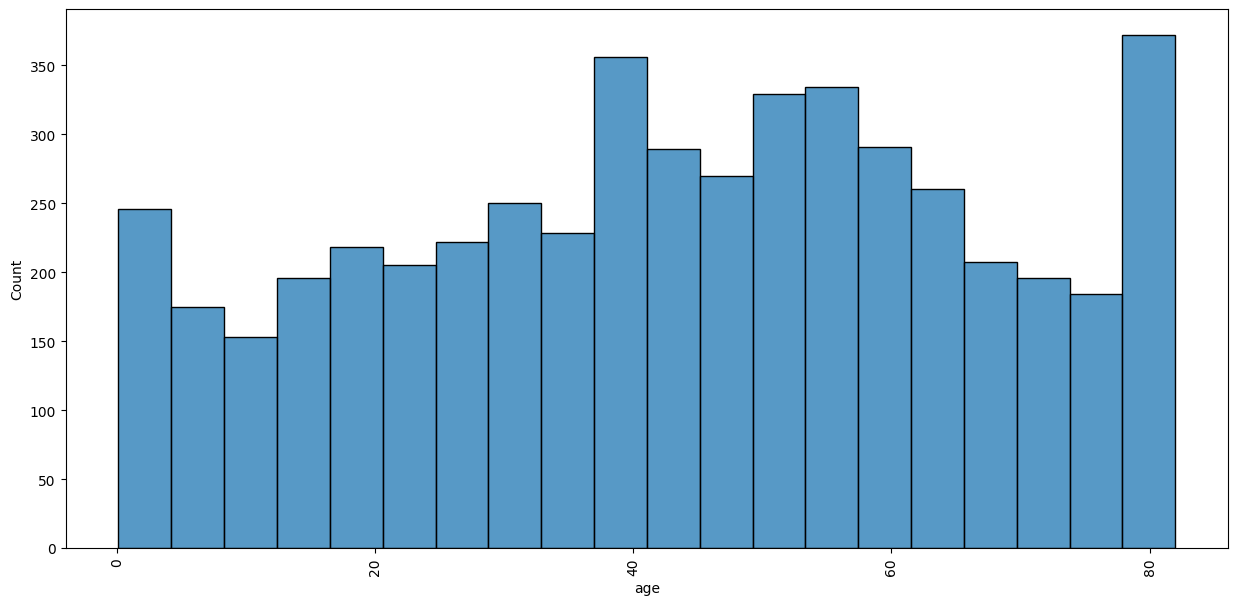

In [16]:
plt.figure(figsize=(15,7))
sns.histplot(data=df_num['age'])
plt.xticks(rotation = 90)
plt.show()

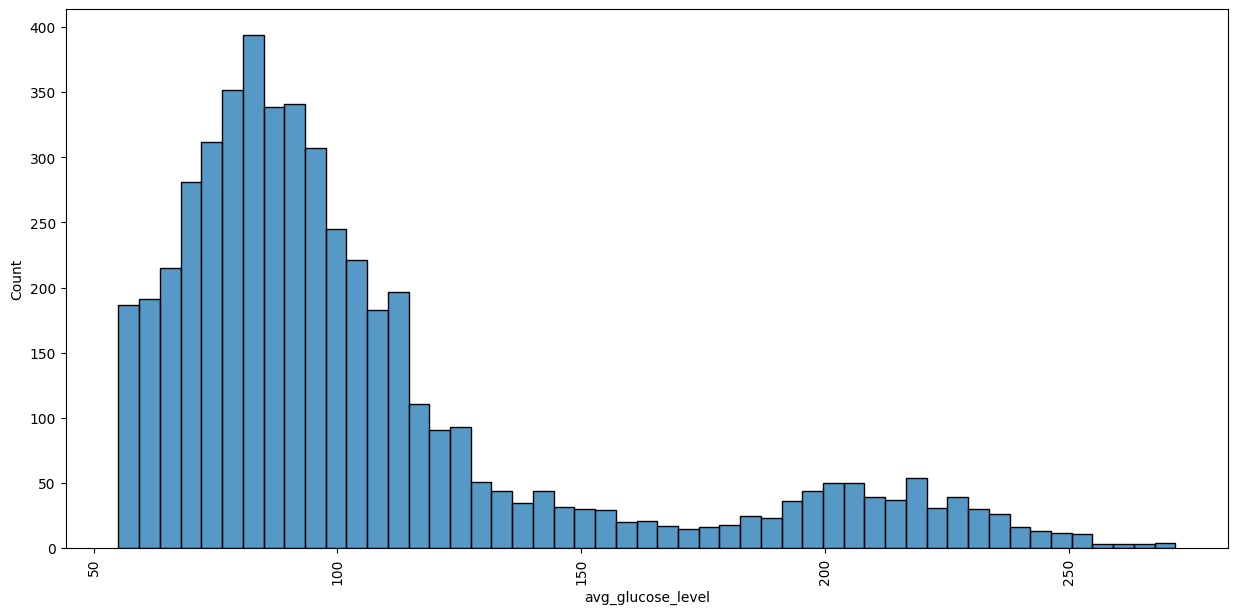

In [17]:
plt.figure(figsize=(15,7))
sns.histplot(data=df_num['avg_glucose_level'])
plt.xticks(rotation = 90)
plt.show()

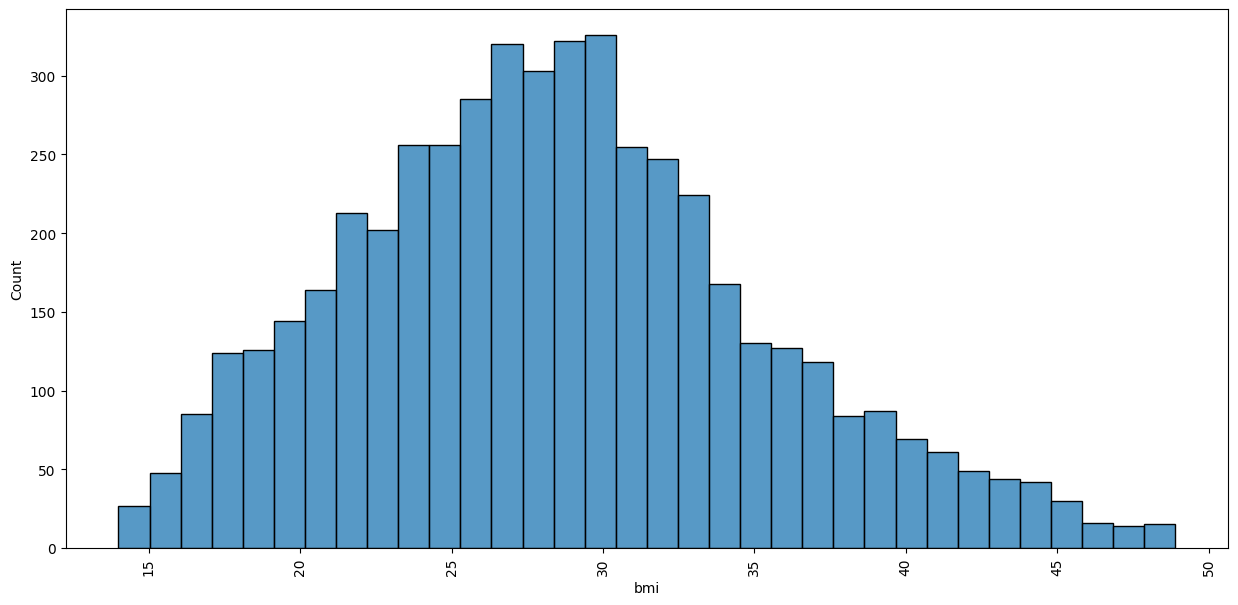

In [18]:
plt.figure(figsize=(15,7))
sns.histplot(data=df_num['bmi'])
plt.xticks(rotation = 90)
plt.show()

Transforming categorical column using encoding 

In [19]:
df['ever_married'] = [ 0 if i !='Yes' else 1 for i in df['ever_married'] ]
df['gender'] = [0 if i != 'Female' else 1 for i in df['gender']]

In [20]:
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,0,67.0,0,1,1,Private,Urban,228.69,36.6,formerly smoked,1
1,0,80.0,0,1,1,Private,Rural,105.92,32.5,never smoked,1
2,1,49.0,0,0,1,Private,Urban,171.23,34.4,smokes,1
3,1,79.0,1,0,1,Self-employed,Rural,174.12,24.0,never smoked,1
4,0,81.0,0,0,1,Private,Urban,186.21,29.0,formerly smoked,1


In [21]:
df=pd.get_dummies(df,columns=['work_type','Residence_type','smoking_status'])

In [22]:
df.sample(10)

,gender,age,hypertension,heart_disease,ever_married,avg_glucose_level,bmi,stroke,work_type_Govt_job,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
2486,0,15.0,0,0,0,190.13,20.7,0,False,True,False,False,False,True,False,False,True,False
4355,0,32.0,0,0,1,72.34,32.2,0,False,True,False,False,True,False,True,False,False,False
4419,1,8.0,0,0,0,120.43,23.5,0,False,False,False,True,True,False,True,False,False,False
1960,0,67.0,0,0,1,208.78,26.7,0,False,True,False,False,True,False,True,False,False,False
1515,1,25.0,0,0,0,78.59,37.2,0,False,True,False,False,False,True,False,False,True,False
2070,1,5.0,0,0,0,73.69,24.8,0,False,False,False,True,True,False,True,False,False,False
816,0,27.0,0,0,1,104.48,36.4,0,False,True,False,False,True,False,False,False,False,True
1090,1,79.0,0,0,1,65.59,28.1,0,False,True,False,False,False,True,False,False,True,False
2609,1,8.0,0,0,0,87.92,14.1,0,False,False,False,True,True,False,True,False,False,False
1232,0,46.0,0,1,1,178.76,24.1,0,False,True,False,False,False,True,False,False,True,False


split the dataset using train test split

In [23]:
from imblearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler

In [24]:
X = df.drop(['stroke'], axis=1)
y = df['stroke']

In [25]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

In [26]:
# smote = SMOTE(sampling_strategy=1.0,random_state=42,k_neighbors=5)

# X_train_smote, y_train_smote = smote.fit_resample(X_train,y_train)

In [27]:
# print("Before SMOTE:")
# print(y_train.value_counts())

# print("After SMOTE:")
# print(y_train_smote.value_counts())

In [28]:
X.shape

(4981, 17)

In [29]:
y.shape

(4981,)

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

Logistic Regression

In [31]:
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(sampling_strategy=1.0, random_state=42, k_neighbors=5)),
    ('classifier', LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000))
])
lr_pipeline.fit(X_train, y_train)
lr_pred = lr_pipeline.predict(X_test)

In [32]:
from sklearn.metrics import confusion_matrix

In [33]:
cm=confusion_matrix(y_test, lr_pred)

In [34]:
print(cm)

[[703 244]
 [  9  41]]


In [35]:
from sklearn.metrics import classification_report, roc_auc_score

# Get prediction probabilities for ROC-AUC
lr_prob = lr_pipeline.predict_proba(X_test)[:, 1]

print("--- Logistic Regression Performance ---")
print(classification_report(y_test, lr_pred, target_names=['No Stroke', 'Stroke']))
print(f"ROC-AUC Score: {roc_auc_score(y_test, lr_prob):.4f}")

--- Logistic Regression Performance ---
              precision    recall  f1-score   support

   No Stroke       0.99      0.74      0.85       947
      Stroke       0.14      0.82      0.24        50

    accuracy                           0.75       997
   macro avg       0.57      0.78      0.55       997
weighted avg       0.95      0.75      0.82       997

ROC-AUC Score: 0.8395


In [36]:
from sklearn import metrics

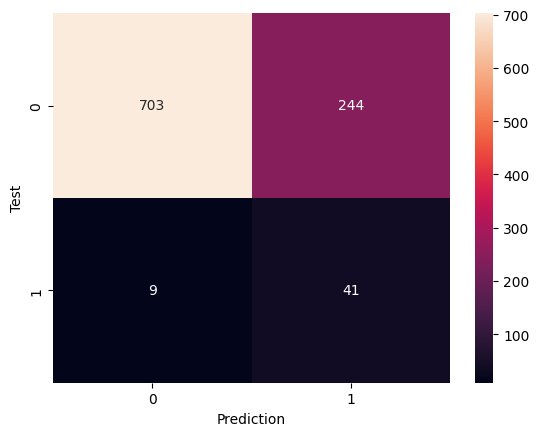

In [37]:
sns.heatmap(confusion_matrix(y_test, lr_pred), annot=True, fmt='d')
plt.xlabel("Prediction")
plt.ylabel("Test")
plt.show()

-- True Negatives (Actual 0, Predicted 0): The model correctly predicted class 0 a total of 703 times.   
-- False Positives (Actual 0, Predicted 1): The model incorrectly predicted class 1 244 times.   
-- False Negatives (Actual 1, Predicted 0): The model incorrectly predicted class 0 when the actual class was 1 a total of 9 times.   
-- True Positives (Actual 1, Predicted 1): The model correctly predicted class 1 41 times.   

Decision Tree

In [38]:
dt_pipeline = Pipeline([
    ('smote', SMOTE(sampling_strategy=1.0, random_state=42, k_neighbors=5)),
    ('classifier', DecisionTreeClassifier(criterion='gini', random_state=42, max_depth=5, class_weight='balanced'))
])

dt_pipeline.fit(X_train, y_train)
dt_pred = dt_pipeline.predict(X_test)

In [39]:
cm=confusion_matrix(y_test,dt_pred)
cm

array([[771, 176],
       [ 24,  26]])

In [40]:
dt_prob = dt_pipeline.predict_proba(X_test)[:, 1]

print("--- Decision Tree Performance ---")
print(classification_report(y_test, dt_pred, target_names=['No Stroke', 'Stroke']))
print(f"ROC-AUC Score: {roc_auc_score(y_test, dt_prob):.4f}")

--- Decision Tree Performance ---
              precision    recall  f1-score   support

   No Stroke       0.97      0.81      0.89       947
      Stroke       0.13      0.52      0.21        50

    accuracy                           0.80       997
   macro avg       0.55      0.67      0.55       997
weighted avg       0.93      0.80      0.85       997

ROC-AUC Score: 0.7879


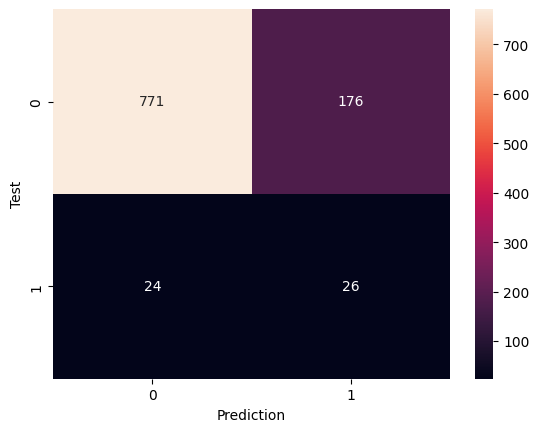

In [41]:
from sklearn.metrics import confusion_matrix

sns.heatmap(confusion_matrix(y_test, dt_pred), annot=True, fmt='d')
plt.xlabel("Prediction")
plt.ylabel("Test")
plt.show()

Random Forest

In [42]:
rf_pipeline = Pipeline([
    ('smote', SMOTE(sampling_strategy=1.0, random_state=42, k_neighbors=5)),
    ('classifier', RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_split=5, class_weight='balanced', min_samples_leaf=2, random_state=42))
])

rf_pipeline.fit(X_train, y_train)
rf_pred = rf_pipeline.predict(X_test)

In [43]:
cm = confusion_matrix(y_test, rf_pred)
cm

array([[913,  34],
       [ 45,   5]])

In [44]:
rf_pred = rf_pipeline.predict(X_test)
rf_prob = rf_pipeline.predict_proba(X_test)[:, 1]
custom_threshold = 0.25
rf_pred_tuned = (rf_prob >= custom_threshold).astype(int)

print("--- Random Forest Performance ---")
print(classification_report(y_test, rf_pred_tuned, target_names=['No Stroke', 'Stroke']))
print(f"ROC-AUC Score: {roc_auc_score(y_test, rf_prob):.4f}")

--- Random Forest Performance ---
              precision    recall  f1-score   support

   No Stroke       0.97      0.82      0.89       947
      Stroke       0.14      0.56      0.23        50

    accuracy                           0.81       997
   macro avg       0.56      0.69      0.56       997
weighted avg       0.93      0.81      0.86       997

ROC-AUC Score: 0.8121


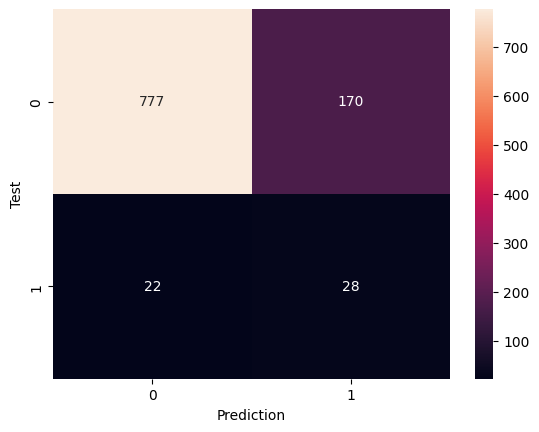

In [45]:
from sklearn.metrics import recall_score, roc_auc_score, precision_score, f1_score

sns.heatmap(confusion_matrix(y_test, rf_pred_tuned), annot=True, fmt='d')
plt.xlabel("Prediction")
plt.ylabel("Test")
plt.show()

In [46]:
models = {
    'Logistic Regression': (lr_pred, lr_prob),
    'Decision Tree': (dt_pred, dt_prob),
    'Random Forest': (rf_pred, rf_prob)
}
comparison_data = []

for name, (preds, probs) in models.items():
    comparison_data.append({
        'Model': name,
        'ROC-AUC': roc_auc_score(y_test, probs),
        'Stroke Recall': recall_score(y_test, preds, pos_label=1),
        'Stroke Precision': precision_score(y_test, preds, pos_label=1, zero_division=0),
        'Stroke F1-Score': f1_score(y_test, preds, pos_label=1)
    })

In [47]:
comparison_df = pd.DataFrame(comparison_data).set_index('Model')
display(comparison_df)

,ROC-AUC,Stroke Recall,Stroke Precision,Stroke F1-Score
Model,,,,
Logistic Regression,0.839451,0.82,0.143860,0.244776
Decision Tree,0.787856,0.52,0.128713,0.206349
Random Forest,0.812080,0.10,0.128205,0.112360
